# 1. Оцінювання параметрів (ОМВ та ОММ)

Дано кратну вибірку $(\xi_1, ..., \xi_n)$ і наступні розподіли

1. Exp($\lambda$ + 1 / $\lambda$)
2. N(0, $\frac{1}{\sigma^2}$)
3. $U[0, \frac{1}{\theta}]$
4. $B(n^2, 0.1)$
5. $\Gamma(\alpha^2, 5)$
6. $\beta(0.65, \frac{1}{\theta})$
7. $p * Exp(5) + (1 - p) * Exp(10)$
8. $Geom(e^{-p})$

Для одного з розподілів (відповідно до варіанта) будудуйте оцінку параметра:
- Методом моментів (ОММ)
- Методом максимальної вірогідності (ОМВ)
- Третю оцінку, яка є лінійною комбінацією 2х оцінок (0.5 ОМВ + 0.5 ОММ)

Чи будуть ці оцінки незміщені? (Можна показати моделюванням, якщо не виходить на листочку)  
Чи будуть вони консистентні? (Можна показати моделюванням, якщо не виходить на листочку)  
Дисперсія якої з оцінок буде найменшою (ОММ, ОМВ чи третя)? (теоретично або моделюванням)  

## Зауваження. Якщо не виходить знайти рішення рівняння аналітичним шляхом, використайте scipy.optimize

## Вимоги
напишіть звіт:  
1. Дайте відповіді на питання
2. Зробить вистновки які з оцінок "кращі"

# Варіант 2

 $X_i \sim N(0, \frac{1}{\sigma^2})$, $\sigma>0$.

**ОММ:**

Момент $\mathbb E[X]=0$ не містить невідомого параметра $\sigma$.

$\mathbb E[X^2]=\operatorname{Var}(X)+(\mathbb E[X])^2=\frac{1}{\sigma^2}+0=\frac{1}{\sigma^2}.$

Вибірковий другий момент — $\frac1n\sum_{i=1}^n X_i^2$. Прирівнюємо його до теоретичного:

$\frac1n\sum_{i=1}^n X_i^2=\frac1{\sigma^2}.$

$\sum_{i=1}^n X_i^2=\frac{n}{\sigma^2}\quad\Rightarrow\quad \sigma^2=\frac{n}{\sum_{i=1}^n X_i^2}.$

Оскільки $\sigma>0$, беремо додатний корінь:

$\boxed{\widehat\sigma_{\rm MM}=\sqrt{\frac{n}{\sum_{i=1}^n X_i^2}}}.$

**ОМВ:**

Щільність одного спостереження: $f(x;\sigma)=\frac{\sigma}{\sqrt{2\pi}}e^{-\sigma^2x^2/2}$.

Для незалежних спостережень функція правдоподібності:

$L(\sigma)=\prod_{i=1}^n f(X_i;\sigma)=\left(\frac{\sigma}{\sqrt{2\pi}}\right)^n e^{-\frac{\sigma^2}{2}\sum_{i=1}^n X_i^2}$.

Логарифмуємо:

$\ell(\sigma)=\log L(\sigma)=n\log\sigma-\frac n2\log(2\pi)-\frac{\sigma^2}{2}\sum_{i=1}^n X_i^2$.

Знаходимо похідну та прирівнюємо до нуля:

$\ell'(\sigma)=\frac n\sigma-\sigma\sum_{i=1}^n X_i^2=0\quad\Rightarrow\quad n=\sigma^2\sum_{i=1}^n X_i^2$.

$\sigma^2=\frac{n}{\sum_{i=1}^n X_i^2}\quad\Rightarrow\quad \boxed{\widehat\sigma_{\rm MLE}=\sqrt{\frac{n}{\sum_{i=1}^n X_i^2}}}$.

Перевірка максимуму: $\ell''(\sigma)=-\frac n{\sigma^2}-\sum_{i=1}^n X_i^2<0$. Отже, $\widehat\sigma_{\rm MLE}=\widehat\sigma_{\rm MM}$.

**Третя оцінка:**

$\widehat\sigma_3=0.5\widehat\sigma_{\rm MLE}+0.5\widehat\sigma_{\rm MM}=\widehat\sigma_{\rm MM}$, оскільки перші дві оцінки збігаються.

**Зміщення:**

Нехай $Z_i=\sigma X_i$. Тоді $Z_i\sim N(0,1)$, тому $Q=\sum_{i=1}^n Z_i^2\sim\chi_n^2$. Оскільки $\sum X_i^2=Q/\sigma^2$, маємо $\widehat\sigma=\sigma\sqrt{n/Q}$.

Щільність $Q$: $f_Q(q)=\frac{q^{n/2-1}e^{-q/2}}{2^{n/2}\Gamma(n/2)}$, $q>0$.

За формулою математичного сподівання:

$\mathbb E[\widehat\sigma]=\int_0^\infty \sigma\sqrt{\frac nq}f_Q(q)\,dq=\frac{\sigma\sqrt n}{2^{n/2}\Gamma(n/2)}\int_0^\infty q^{(n-3)/2}e^{-q/2}\,dq$.

Використовуємо гамма-інтеграл $\int_0^\infty q^{a-1}e^{-q/2}\,dq=2^a\Gamma(a)$, де $a=(n-1)/2$:

$\int_0^\infty q^{(n-3)/2}e^{-q/2}\,dq=2^{(n-1)/2}\Gamma\!\left(\frac{n-1}{2}\right)$.

Тому $\mathbb E[\widehat\sigma]=\sigma\sqrt{\frac n2}\frac{\Gamma((n-1)/2)}{\Gamma(n/2)}$.

Оскільки $g(q)=\sqrt{n/q}$ опукла, а $\mathbb E[Q]=n$, за нерівністю Єнсена $\mathbb E[\sqrt{n/Q}]>\sqrt{n/\mathbb E[Q]}=1$. Отже, $\mathbb E[\widehat\sigma]>\sigma$, тобто оцінка зміщена вгору.



**Консистентність:**

За ЗВЧ $\frac1n\sum_{i=1}^n X_i^2\xrightarrow{P}\mathbb E[X^2]=\frac1{\sigma^2}$.

Тому $\widehat\sigma=\left(\frac1n\sum_{i=1}^n X_i^2\right)^{-1/2}\xrightarrow{P}\left(\frac1{\sigma^2}\right)^{-1/2}=\sigma$. Отже, оцінка консистентна.

Усі три оцінки збігаються для кожної вибірки, тому їхні дисперсії однакові.


In [14]:
import numpy as np

X = np.array([
    0.06704377, -1.18488209, 0.56093463, 2.28920627, -0.52843351,
    1.64094723, -2.41745054, 0.63898792, 1.69417600, 0.22749164,
    -0.69864633, -0.16385323, 1.41229225, 1.77067654, -1.32968981,
    0.25585254, 1.09594198, 0.80643983, 0.73262927, 0.97645904
])

n = len(X)
sigma_mm = 1 / np.sqrt(np.mean(X**2))
sigma_ml = np.sqrt(n / np.sum(X**2))
sigma_3 = 0.5 * sigma_ml + 0.5 * sigma_mm

print(f"n = {n}")
print(f"mean(X^2) = {np.mean(X**2):.6f}")
print(f"Оцінка ОММ = {sigma_mm:.6f}")
print(f"Оцінка ОМВ = {sigma_ml:.6f}")
print(f"Третя оцінка = {sigma_3:.6f}")
print(f"Оцінене станд. відх. 1/sigma = {1/sigma_ml:.6f}")

n = 20
mean(X^2) = 1.496493
Оцінка ОММ = 0.817453
Оцінка ОМВ = 0.817453
Третя оцінка = 0.817453
Оцінене станд. відх. 1/sigma = 1.223312


# 2. Застосування

Вам дано вибірку X. За її допомогою, оцініть параметри розподілу вибірки, у припущенні, що розподіл - той, що і у вашому варіанті.

1. Побудуйте емпіричну функцію розподілу
2. Побудуйте теоретичний розподіл на основі оцінених параметрів (відповідно до варіанту)
3. Чи відповідає оцінений розподіл розподілу вибірки?
4. Напишіть висновок

$Z=\sigma X\sim N(0,1)$, ФР $X$ буде $F_X(x)=P(X\le x)=P(Z\le\sigma x)=\Phi(\sigma x)$, де $\Phi$ — ФР стандартного нормального закону.

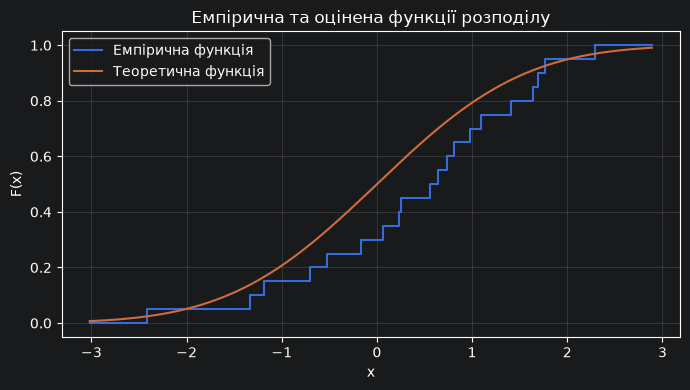

In [15]:
import matplotlib.pyplot as plt
from scipy.stats import norm

sigma_hat = sigma_ml
x_sorted = np.sort(X)
# Межі графіка трохи ширші за межі вибірки
grid = np.linspace(min(X) - 0.6, max(X) + 0.6, 500)

# Емпірична функція розподілу
x_ecdf = np.r_[grid[0], x_sorted, grid[-1]]
y_ecdf = np.r_[0, np.arange(1, n + 1) / n, 1]

# Теоретична функція розподілу N(0, 1 / sigma_hat^2)
y_theory = norm.cdf(grid, loc=0, scale=1 / sigma_hat)

plt.figure(figsize=(7, 4))
plt.step(x_ecdf, y_ecdf, where="post", label="Емпірична функція")
plt.plot(grid, y_theory, label="Теоретична функція")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.title("Емпірична та оцінена функції розподілу")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
X = np.array([ 0.06704377, -1.18488209,  0.56093463,  2.28920627, -0.52843351,
        1.64094723, -2.41745054,  0.63898792,  1.694176  ,  0.22749164,
       -0.69864633, -0.16385323,  1.41229225,  1.77067654, -1.32968981,
        0.25585254,  1.09594198,  0.80643983,  0.73262927,  0.97645904])